# Decode the Bioreactor — 08 Tobias' v3 (soft sensors) in our pipeline + his next ideas
Tobias' hybrid v3 (branch `hybrid_v3_tr`, 7.67 in his 7-fold CV) ported to `src/bioreactor/` and scored on **our** split (5 dev folds, 10 hold-out batches), so all numbers are comparable with notebooks 03–07.

**Stage 1** (base prediction, out-of-fold for every batch) — choose with `STAGE1`:
- `"mech"`: our mechanistic model (cached parameters per fold),
- `"mech_base"`: **idea 3** — the pH-control base (volume the feed log does not explain) enters the ODE as a measured byproduct-production flux, `dP += Ybase · base(t) / V`,
- `"tobias"`: his neural-net hybrid, read from his CSV output. **Idea 2** (glucose-uptake correction in his stage 1) = his stage 1 run with `--outputs mu,glc,lac`, then pointed to here (see section 0).

**Stage 2** (`src/bioreactor/v3.py`): soft-sensor corrections on top of stage 1 (cells: gradient boosting on day-0 state and feed deviations; substrate: bolus soft sensor + per-day ridge; byproduct: smooth-in-day ridge on the base-volume sensor), MAPE-optimal scaling, 50/50 blend with a bagged gradient-boosting branch.
**Idea 1**: similarity member for VCD/TCD (k most similar training batches at day 0) as optional third blend member.

Sensors (`src/bioreactor/sensors.py`) use only the feed and volume log → available for test batches.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor import model as M
from bioreactor.model import NAMES, set_options, model_tag, predict_at_obs
from bioreactor.fit import fit_staged, initial_from_data
from bioreactor.sensors import feed_features, sensor_features, base_rate
from bioreactor.v3 import (build_rows, check_rows, HybridBranch, DataDrivenBranch, CellSimilarity,
                           finalize, score)

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

# ---------------- settings
STAGE1 = "mech"              # "mech" | "mech_base" (idea 3) | "tobias" (idea 2 via TOBIAS_DIR)
TOBIAS_DIR = ROOT / "outputs" / "hybrid"        # his stage-1 output (see section 0)
TOBIAS_MODEL = "states"                         # model name inside his CSV
USE_SIMILARITY = True        # idea 1: third blend member for VCD/TCD
SIM_K, SIM_WEIGHT = 5, 1 / 3
N_BAGS = 10                  # data-driven branch bootstrap bags

MAX_NFEV_STAGE, MAX_NFEV, N_STARTS = 20, 60, 1
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)
CACHE = ROOT / "outputs" / "params_cache"; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

## 0. Soft sensors
Pooled sample volume (from the late, steady volume loss) and the base added by the pH controller per batch. Train and test batches should look alike.

In [2]:
F = feed_features(df)
sens_batch, sens_day, sample = sensor_features(df)
BASE = base_rate(df, sample)          # per batch: base added between samples (for idea 3)
print(f"sample volume {sample:.4f}; base added: mean {sens_batch.base_tot.mean():.3f}, sd {sens_batch.base_tot.std():.3f}; "
      f"batches with early bolus: {(sens_batch.A_early > 0).sum()}")
sens_batch.assign(set=np.where(sens_batch.index.isin(test_ids), "test", "train")).groupby("set").mean().round(4)

sample volume 0.0514; base added: mean 0.182, sd 0.022; batches with early bolus: 10


,base_to3,base_to4,base_to5,base_tot,A11,A12,A_early
set,,,,,,,
test,0.1086,0.1581,0.1837,0.1782,0.0048,0.0043,0.0010
train,0.1096,0.1572,0.1810,0.1826,0.0053,0.0043,0.0006


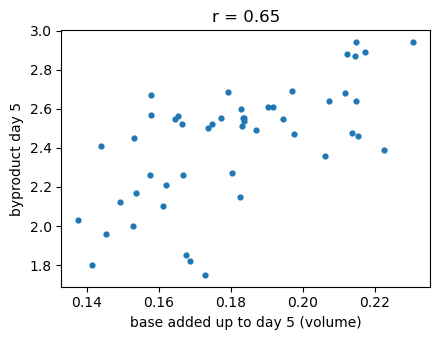

In [3]:
# does the base sensor track the byproduct? (training batches, measured byproduct on day 5)
obs5 = df[df.vcd.notna() & (df.elapsed_time.round() == 5)].set_index("batch_id").byproduct
j = sens_batch.join(obs5.rename("byproduct_d5"), how="inner")
plt.figure(figsize=(4.5, 3.5)); plt.scatter(j.base_to5, j.byproduct_d5, s=12)
plt.xlabel("base added up to day 5 (volume)"); plt.ylabel("byproduct day 5"); plt.title(f"r = {j.base_to5.corr(j.byproduct_d5):.2f}")
plt.tight_layout(); plt.show()

**Using Tobias' stage 1 (idea 2)** — on his branch his output is in `outputs/hybrid/`. Copy the two files into this branch's folder (does not switch branch):
```
git checkout hybrid_v3_tr -- outputs/hybrid/predictions_vs_measured.csv outputs/hybrid/holdout_predictions.csv
```
For idea 2 (his net also corrects glucose uptake), run on his branch / in Renku:
```
python src/hybrid_model.py --variants states --outputs mu,glc,lac --out outputs/hybrid_glc
```
copy `outputs/hybrid_glc/` over the same way and set `TOBIAS_DIR = ROOT / "outputs" / "hybrid_glc"`.
*Caveat*: his stage-1 out-of-fold predictions come from his 7 folds over all 49 batches, so our hold-out batches were in the training data of the stage-1 models that predicted our dev batches (a small leak into the hold-out check, not into CV).

## 1. Stage 1: out-of-fold base predictions for all 61 batches

In [4]:
def mech_params(ids, tag, arr_kw):
    """Mechanistic parameters fitted on `ids` for the active model variant, cached.
    v1 keeps the old cache names (fold0.csv ...), other variants get a suffix."""
    f = CACHE / (f"{tag}.csv" if model_tag() == "v1" else f"{tag}_{model_tag()}.csv")
    if USE_CACHE and f.exists():
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
        if list(s.index) == NAMES:
            print(f"[{tag} {model_tag()}] from cache"); return s.values
    t0 = time.time()
    p, _ = fit_staged(to_arrays(df, ids, **arr_kw), None, p_init=initial_from_data(df, ids),
                      max_nfev_stage=MAX_NFEV_STAGE, max_nfev_final=MAX_NFEV,
                      n_starts=N_STARTS, verbose=False, **FIT_KW)
    pd.Series(p, index=NAMES).to_csv(f); print(f"[{tag} {model_tag()}] fit {time.time()-t0:.0f} s")
    return p

def s1_frame(p, ids, mask, arr_kw):
    a = to_arrays(df, ids, sample_mask=mask, **arr_kw)
    out = []
    for b, t, y in zip(a.ids, a.obs_t, predict_at_obs(p, a)):
        out.append(pd.DataFrame({"batch_id": b, "t": t, **{f"s1_{s}": y[:, i] for i, s in enumerate(STATES)}}))
    return pd.concat(out)

def stage1_mech(base_flux):
    """dev batch in fold f <- fitted on the other dev folds; hold-out <- fitted on all dev;
    test <- fitted on all 49. So every batch's s1 comes from a model that never saw it."""
    set_options(base_flux=base_flux)
    arr_kw = dict(base=BASE) if base_flux else {}
    parts = []
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        parts.append(s1_frame(mech_params(tr_, f"fold{f}", arr_kw), va_, "measured", arr_kw))
    parts.append(s1_frame(mech_params(dev_ids, "dev_all", arr_kw), hold_ids, "measured", arr_kw))
    p_all = mech_params(train_ids, "all49", arr_kw)
    parts.append(s1_frame(p_all, test_ids, "predict", arr_kw))
    return pd.concat(parts, ignore_index=True), p_all

def stage1_tobias(d):
    s = pd.read_csv(d / "predictions_vs_measured.csv", dtype={"batch_id": str})
    s = s[(s.split == "held-out (CV)") & (s.model == TOBIAS_MODEL)]
    w = s.pivot_table(index=["batch_id", "elapsed_time"], columns="variable", values="predicted").reset_index()
    h = pd.read_csv(d / "holdout_predictions.csv", dtype={"batch_id": str})       # his "holdout" = our test
    w = pd.concat([w, h[["batch_id", "elapsed_time", *STATES]]], ignore_index=True)
    w = w.rename(columns={"elapsed_time": "t", **{s_: f"s1_{s_}" for s_ in STATES}})
    # template times are rounded -> map to the exact data times
    exact = df[df.volume.notna()][["batch_id", "elapsed_time"]]
    exact = exact.assign(t_key=exact.elapsed_time.round(6))
    w = w.assign(t_key=w.t.round(6)).merge(exact, on=["batch_id", "t_key"], how="left")
    assert w.elapsed_time.notna().all(), "could not match Tobias' times to the data"
    return w.drop(columns=["t", "t_key"]).rename(columns={"elapsed_time": "t"})

t0 = time.time()
if STAGE1 == "tobias":
    S1 = stage1_tobias(TOBIAS_DIR); P_ALL = None
else:
    S1, P_ALL = stage1_mech(base_flux=(STAGE1 == "mech_base"))
print(f"stage 1 '{STAGE1}': {len(S1)} rows, {time.time()-t0:.0f} s")

obs = df[df.vcd.notna() & (df.elapsed_time > 0)][["batch_id", "elapsed_time", *STATES]]
obs = obs.rename(columns={"elapsed_time": "t", **{s: f"obs_{s}" for s in STATES}})
rows = build_rows(F, sens_batch, sens_day, S1, obs)
check_rows(rows)
rows["role"] = rows.batch_id.map(splits.set_index("batch_id").role)
rows["fold"] = rows.batch_id.map(fold_of)
print(rows.role.value_counts().to_dict())

[fold0 v1] from cache
[fold1 v1] from cache
[fold2 v1] from cache
[fold3 v1] from cache
[fold4 v1] from cache
[dev_all v1] from cache
[all49 v1] from cache
stage 1 'mech': 793 rows, 1 s
{'dev': 507, 'test': 156, 'holdout': 130}


## 2. Cross-validation on the dev folds
Stage 2 is fitted on the training folds only. Rows: stage 1 alone, the two v3 branches, the v3 blend, and v3 + similarity (idea 1).

In [5]:
def run_fold(tr, va):
    hyb = HybridBranch().fit(tr).predict(va)
    dd = DataDrivenBranch(n_bags=N_BAGS).fit(tr).predict(va)
    preds = {"stage1": pd.DataFrame({v: va["s1_" + v] for v in STATES}),
             "v3_hybrid": hyb, "v3_datadriven": dd, "v3_final": finalize(hyb, dd)}
    if USE_SIMILARITY:
        sim = CellSimilarity(k=SIM_K).fit(tr).predict(va)
        preds["v3_final+similarity"] = finalize(hyb, dd, sim=sim, w_sim=SIM_WEIGHT)
    return preds

RUN_CV = True
if RUN_CV:
    dev = rows[rows.role == "dev"]
    tabs, oof = [], []
    t0 = time.time()
    for f in range(5):
        tr, va = dev[dev.fold != f], dev[dev.fold == f]
        preds = run_fold(tr, va)
        tabs.append(pd.DataFrame({n: score(va, P) for n, P in preds.items()}).T.assign(fold=f))
        for n, P in preds.items():          # absolute % error per row, for the by-day plot
            for v in STATES:
                oof.append(pd.DataFrame({"variant": n, "state": v, "day": va.day.values,
                                         "ape": 100 * np.abs(P[v].to_numpy() / va["obs_" + v].to_numpy() - 1)}))
    cv = pd.concat(tabs).rename_axis("variant").reset_index()
    print(f"{time.time()-t0:.0f} s")
    display(cv.groupby("variant")[STATES + ["score"]].agg(["mean", "std"]).round(2).sort_values(("score", "mean")))
    cv.to_csv(ROOT / "outputs" / f"cv_scores_v3_{STAGE1}.csv", index=False)

107 s


vcd          tcd       substrate       byproduct        \
                      mean   std   mean   std      mean   std      mean   std   
variant                                                                         
v3_final+similarity   7.27  0.50   7.18  0.52      8.12  1.46      9.23  1.20   
v3_final              7.40  0.39   7.28  0.34      8.12  1.46      9.23  1.20   
v3_hybrid             7.40  0.49   7.29  0.47      8.85  1.61      9.77  1.00   
v3_datadriven         7.82  0.43   7.67  0.43      9.43  1.54      9.43  1.31   
stage1               10.77  0.50  11.62  0.72     15.09  1.68     16.79  2.66   

                     score        
                      mean   std  
variant                           
v3_final+similarity   7.95  0.55  
v3_final              8.01  0.47  
v3_hybrid             8.33  0.40  
v3_datadriven         8.59  0.67  
stage1               13.57  0.52

Error by day (out-of-fold on the dev batches).

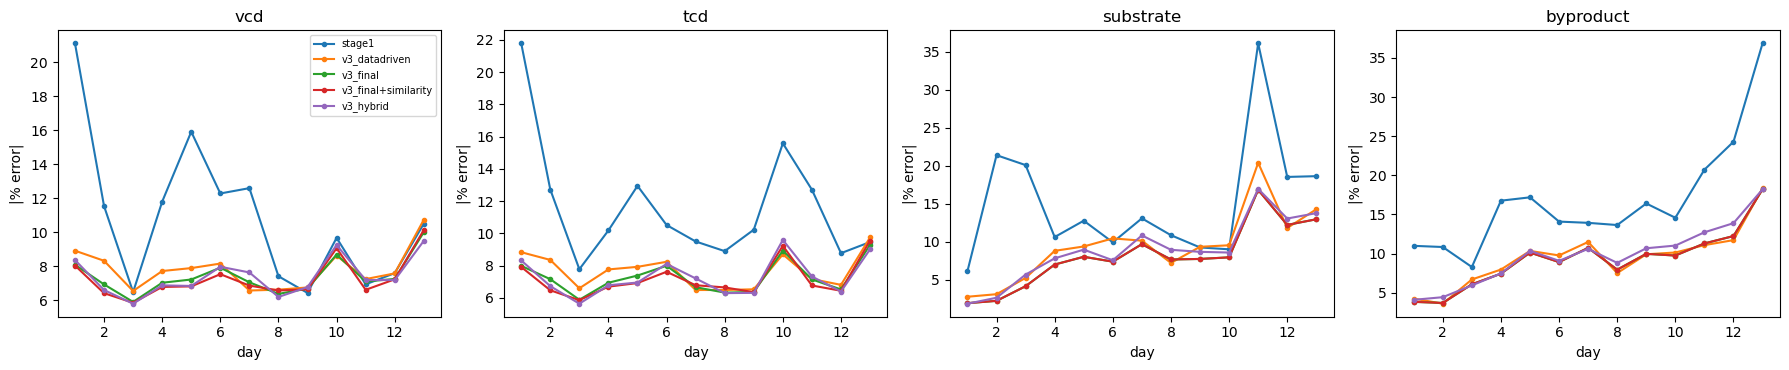

In [6]:
if RUN_CV:
    E = pd.concat(oof).groupby(["variant", "state", "day"]).ape.mean().reset_index()
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    for a, v in zip(ax, STATES):
        for n, g in E[E.state == v].groupby("variant"):
            a.plot(g.day, g.ape, "o-", ms=3, label=n)
        a.set_title(v); a.set_xlabel("day"); a.set_ylabel("|% error|")
    ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. Hold-out check — once, after choosing from CV
Stage 2 fitted on all 39 dev batches, scored on the 10 hold-out batches (their stage-1 predictions come from the model fitted on dev only).

In [10]:
RUN_HOLDOUT = True
if RUN_HOLDOUT:
    tr, va = rows[rows.role == "dev"], rows[rows.role == "holdout"]
    preds = run_fold(tr, va)
    display(pd.DataFrame({n: score(va, P) for n, P in preds.items()}).T.round(2).sort_values("score"))

,vcd,tcd,substrate,byproduct,score
v3_final+similarity,6.23,6.19,6.72,8.15,6.82
v3_final,6.62,6.60,6.72,8.15,7.02
v3_hybrid,6.68,6.79,7.23,9.01,7.43
v3_datadriven,7.25,7.15,8.27,8.41,7.77
stage1,10.76,10.93,12.50,12.32,11.63


## 4. Final: stage 2 on all 49 batches → submission
Writes `outputs/submission_v3_<stage1>[_sim].csv`.

In [8]:
RUN_FINAL = False
if RUN_FINAL:
    tr, te = rows[rows.role.isin(["dev", "holdout"])], rows[rows.role == "test"].copy()
    hyb = HybridBranch().fit(tr).predict(te)
    dd = DataDrivenBranch(n_bags=N_BAGS).fit(tr).predict(te)
    sim = CellSimilarity(k=SIM_K).fit(tr).predict(te) if USE_SIMILARITY else None
    P = finalize(hyb, dd, sim=sim, w_sim=SIM_WEIGHT)
    assert P.notna().all().all() and (P > 0).all().all()

    sub = tmpl.copy(); sub[STATES] = sub[STATES].astype(float)          # template columns are int zeros
    te = te.assign(**{v: P[v].to_numpy() for v in STATES})
    for b, g in sub.groupby("batch_id", sort=False):
        gt = te[te.batch_id == b].sort_values("t")
        assert len(g) == len(gt) and np.allclose(np.sort(g.elapsed_time.values), gt.t.values, atol=1e-3), b
        sub.loc[g.sort_values("elapsed_time").index, STATES] = gt[STATES].to_numpy()
    assert sub[STATES].notna().all().all()
    out = ROOT / "outputs" / f"submission_v3_{STAGE1}{'_sim' if USE_SIMILARITY else ''}.csv"
    sub.to_csv(out, index=False); print("written", out)
    display(sub.head())

## 5. Idea 3 — what did the base flux inside the ODE learn?
Only for `STAGE1 = "mech_base"`: `Ybase` converts base volume into byproduct. Compare the mechanistic byproduct error with and without it in the CV table above (`stage1` row of each run).

In [9]:
if STAGE1 == "mech_base" and P_ALL is not None:
    print(pd.Series(P_ALL, index=NAMES).round(4).to_string())